# 01 · First look at the export

A year of nights from my watch (2025), plus the caffeine log I kept in a notes app.
The raw files are private, so `data/` holds a synthetic stand-in with the same shape — see `data/generate.py`.

In [1]:
from sleep_patterns.io import load_caffeine, load_sleep

sleep = load_sleep()
caffeine = load_caffeine()
sleep.head()

,start,end,awakenings,efficiency
0,2025-01-01 23:23:00,2025-01-02 06:21:00,2,87.9
1,2025-01-02 23:33:00,2025-01-03 05:17:00,1,93.8
2,2025-01-04 00:04:00,2025-01-04 06:55:00,2,86.5
3,2025-01-04 23:57:00,2025-01-05 08:34:00,0,89.4
4,2025-01-05 23:28:00,2025-01-06 06:18:00,0,94.3


In [2]:
sleep.describe()

,start,end,awakenings,efficiency
count,359,359,359.000000,359.000000
mean,2025-07-01 14:23:10.194986,2025-07-01 21:12:39.442897,1.409471,89.246797
min,2025-01-01 23:23:00,2025-01-02 06:21:00,0.000000,80.900000
25%,2025-04-02 11:39:30,2025-04-02 17:46:00,1.000000,87.100000
50%,2025-06-30 00:08:00,2025-06-30 05:25:00,1.000000,89.400000
75%,2025-10-01 12:11:00,2025-10-01 19:27:30,2.000000,91.450000
max,2025-12-31 22:21:00,2026-01-01 04:55:00,7.000000,97.100000
std,NaN,NaN,1.226805,3.230534


The watch logs *sessions*, not nights. Some are clearly not a night's sleep —
short afternoon naps, and one ~15 hour session from a day it never came off.

In [3]:
hours = (sleep["end"] - sleep["start"]).dt.total_seconds() / 3600
sleep.assign(hours=hours.round(2)).query("hours < 2 or hours > 14")

,start,end,awakenings,efficiency,hours
7,2025-01-08 14:04:00,2025-01-08 14:22:00,0,95.0,0.3
44,2025-02-16 13:35:00,2025-02-16 14:11:00,0,95.0,0.6
46,2025-02-17 15:58:00,2025-02-18 07:28:00,0,95.0,15.5
106,2025-04-18 15:42:00,2025-04-18 16:12:00,0,95.0,0.5
149,2025-05-31 15:15:00,2025-05-31 15:39:00,0,95.0,0.4
301,2025-11-02 14:20:00,2025-11-02 15:02:00,0,95.0,0.7


## Cleaning

`nightly()` drops anything under 2h or over 14h, keeps the longest session per night,
and assigns post-midnight bedtimes to the evening before (a 00:40 bedtime on Saturday is still Friday night).

In [4]:
from sleep_patterns.clean import nightly

nights = nightly(sleep)
print(f"{len(sleep)} sessions -> {len(nights)} nights, {365 - len(nights)} missing")
nights[["night", "weekday", "hours", "awakenings", "efficiency"]].head()

359 sessions -> 353 nights, 12 missing


,night,weekday,hours,awakenings,efficiency
0,2025-01-01,Wednesday,6.966667,2,87.9
1,2025-01-02,Thursday,5.733333,1,93.8
2,2025-01-03,Friday,6.850000,2,86.5
3,2025-01-04,Saturday,8.616667,0,89.4
4,2025-01-05,Sunday,6.833333,0,94.3


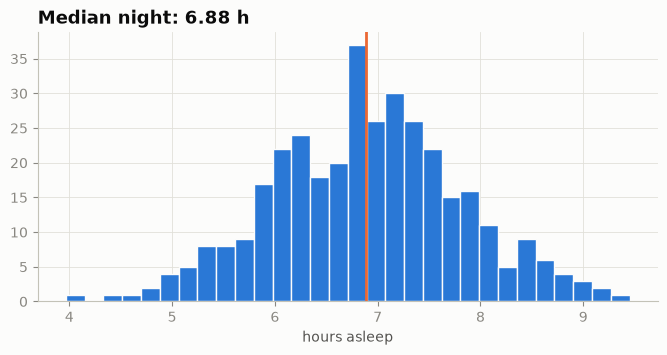

In [5]:
import matplotlib.pyplot as plt
from sleep_patterns import plots

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(nights["hours"], bins=30, color=plots.BLUE, edgecolor=plots.SURFACE)
ax.axvline(nights["hours"].median(), color=plots.ORANGE)
ax.set_xlabel("hours asleep")
ax.set_title(f"Median night: {nights['hours'].median():.2f} h");